# VehicleAI – Huấn luyện mô hình Keras và đánh giá trên dữ liệu kiểm thử

**Bài nộp HD 4.4 – Xử lý ảnh kỹ thuật số**

Notebook này **huấn luyện một mô hình phân loại ảnh 4 lớp** (`bus`, `car`, `truck`, `van`) bằng TensorFlow/Keras, sử dụng ảnh của dự án VehicleAI. Kết quả là **một mô hình `.keras` được huấn luyện thật** và bộ dữ liệu test có thể kiểm tra lại.

> **Phân biệt:** mô hình Keras bổ sung này là **bộ phân loại ảnh**, không phải mô hình YOLO phát hiện vật thể `.pt` của ứng dụng VehicleAI. Không dùng mô hình `.keras` này như trọng số YOLO phát hiện 48 loại xe.

### Chuẩn bị trước khi chạy

1. Tải file `VehicleAI_Dataset_4_Lop.zip` đi kèm gói nộp.
2. Vào [Google Drive](https://drive.google.com/), tạo thư mục `My Drive/VehicleAI_NopBai`.
3. Tải `VehicleAI_Dataset_4_Lop.zip` vào thư mục vừa tạo (không cần giải nén trên Drive).
4. Trong Colab: `Runtime` → `Change runtime type` → chọn GPU nếu có, rồi chạy các ô từ trên xuống.
5. Sau khi chạy, **giữ nguyên kết quả ô code**, chọn `File` → `Save a copy in Drive` hoặc lưu notebook hiện tại và chia sẻ `Anyone with the link` → `Viewer`.

**Dữ liệu trong gói hiện tại:** train 1.120 ảnh, validation 280 ảnh, test 173 ảnh, 4 nhãn. Bộ test trong ZIP đã sửa bị thiếu so với con số 280 test được báo cáo trước đây, vì vậy kết quả notebook này **chỉ được đánh giá trên 173 ảnh hiện có**. Không công bố độ chính xác nếu chưa chạy xong.


## 1. Kiểm tra môi trường Colab / TensorFlow

In [ ]:
import importlib.util, subprocess, sys
packages = {'tensorflow': 'tensorflow>=2.16', 'sklearn': 'scikit-learn', 'matplotlib':'matplotlib', 'pandas':'pandas', 'PIL':'Pillow'}
missing = [pkg for module,pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Cài gói còn thiếu:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
print('TensorFlow:', tf.__version__)
print('GPU hiện có:', tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU hiện có: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Kết nối Google Drive và xác nhận dữ liệu đã tải lên

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
FOLDER = Path('/content/drive/MyDrive/VehicleAI_NopBai')
FOLDER.mkdir(parents=True, exist_ok=True)
ZIP_PATH = FOLDER / 'VehicleAI_Dataset_4_Lop.zip'
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f'Chưa thấy {ZIP_PATH}. Hãy tải file ZIP vào đúng thư mục trên Google Drive.')
print('Đã tìm thấy:', ZIP_PATH, '| Kích thước:', round(ZIP_PATH.stat().st_size/1024/1024, 2), 'MB')


Mounted at /content/drive
Đã tìm thấy: /content/drive/MyDrive/VehicleAI_NopBai/VehicleAI_Dataset_4_Lop.zip | Kích thước: 1.72 MB


## 3. Giải nén và kiểm tra 3 tập train/val/test

In [ ]:
import zipfile
from collections import Counter
DATA_HOME=Path('/content/vehicleai_keras_data')
DATA_HOME.mkdir(exist_ok=True, parents=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    # Bộ ZIP trong gói có cấu trúc chính xác: vehicle_classification/{train,val,test}/{class}/{image}
    for m in z.infolist():
        if '..' in Path(m.filename).parts or Path(m.filename).is_absolute():
            raise ValueError('ZIP chứa đường dẫn không an toàn: '+m.filename)
    z.extractall(DATA_HOME)
DATA_ROOT = DATA_HOME / 'vehicle_classification'
CLASSES=['bus','car','truck','van']
counts={}
for split in ['train','val','test']:
    assert (DATA_ROOT/split).is_dir(), f'Thiếu thư mục {split}'
    counts[split]={}
    for cl in CLASSES:
        d=DATA_ROOT/split/cl
        assert d.is_dir(), f'Thiếu lớp {cl} trong {split}'
        counts[split][cl]=sum(1 for f in d.iterdir() if f.suffix.lower() in ['.jpg','.jpeg','.png','.webp'])
        assert counts[split][cl]>0, f'Thiếu ảnh: {d}'
df_counts=pd.DataFrame(counts).T
display(df_counts.assign(Tong=df_counts.sum(axis=1)))
print('Số ảnh test thực tế:', df_counts.loc['test'].sum())


,bus,car,truck,van,Tong
train,280,280,280,280,1120
val,70,70,70,70,280
test,19,67,48,39,173


Số ảnh test thực tế: 173


## 4. Tạo bộ dữ liệu TensorFlow (không trộn test vào train)

In [ ]:
IMG_SIZE=(160,160)
BATCH_SIZE=32
SEED=42
make_ds=lambda split, shuffle: tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT/split, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='int', shuffle=shuffle, seed=SEED if shuffle else None
)
train_ds=make_ds('train',True)
val_ds=make_ds('val',False)
test_ds=make_ds('test',False)
assert list(train_ds.class_names)==CLASSES
assert list(val_ds.class_names)==CLASSES
assert list(test_ds.class_names)==CLASSES
AUTOTUNE=tf.data.AUTOTUNE
train_ds=train_ds.prefetch(AUTOTUNE)
val_ds=val_ds.prefetch(AUTOTUNE)
test_ds=test_ds.prefetch(AUTOTUNE)
print('Thứ tự nhãn:',CLASSES)


Found 1120 files belonging to 4 classes.
Found 280 files belonging to 4 classes.
Found 173 files belonging to 4 classes.
Thứ tự nhãn: ['bus', 'car', 'truck', 'van']


## 5. Xem mẫu ảnh huấn luyện

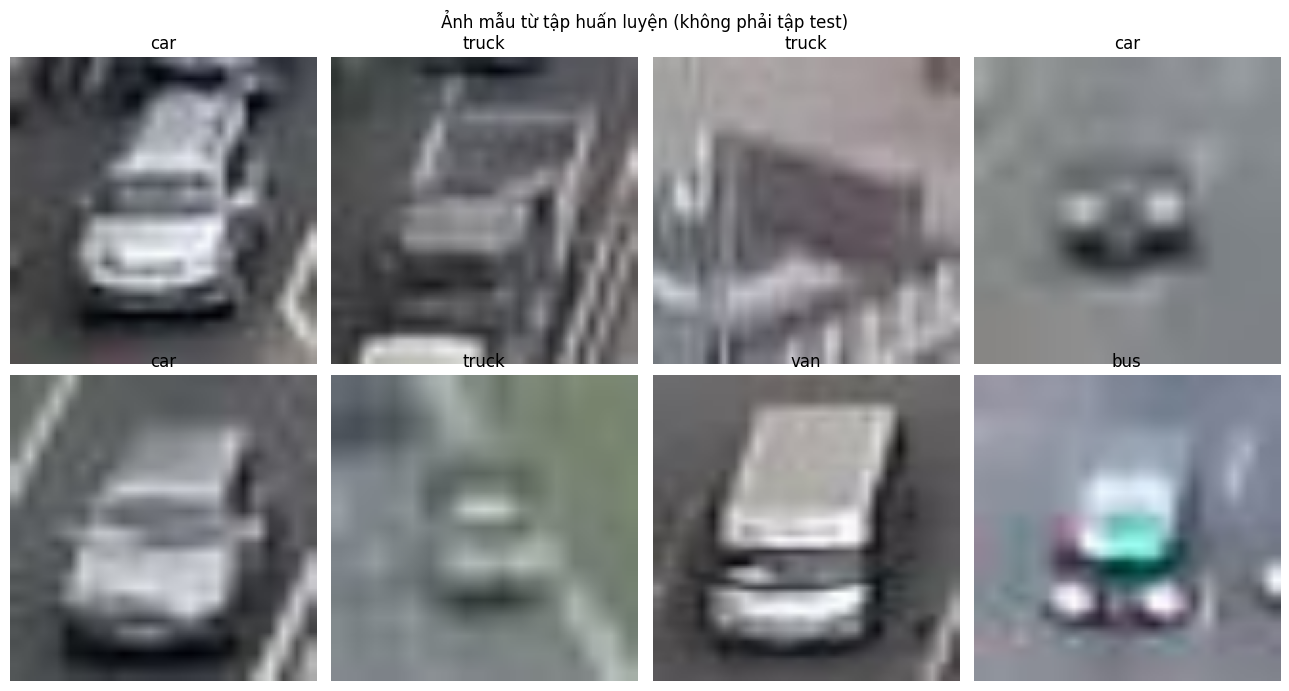

In [ ]:
fig, axes=plt.subplots(2,4,figsize=(13,7))
for images,labels in train_ds.take(1):
    for ax,img,label in zip(axes.flat, images[:8], labels[:8]):
        ax.imshow(tf.cast(img,tf.uint8).numpy())
        ax.set_title(CLASSES[int(label)])
        ax.axis('off')
plt.suptitle('Ảnh mẫu từ tập huấn luyện (không phải tập test)')
plt.tight_layout()
plt.show()


## 6. Xây dựng mô hình Keras (MobileNetV2 transfer learning)

Tải backbone MobileNetV2 tiền huấn luyện trên ImageNet. Nếu Colab không tải được trọng số gốc do lỗi mạng, chạy lại ô sau khi kết nối mạng; **không thay bằng trọng số giả**. Chỉ huấn luyện tầng phân loại ở bước đầu.


In [ ]:
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
augmentation=tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.08),
], name='augmentation')
base_model=MobileNetV2(input_shape=(160,160,3), include_top=False, weights='imagenet')
base_model.trainable=False
inputs=tf.keras.Input(shape=(160,160,3), name='image')
x=augmentation(inputs)
x=layers.Rescaling(1./127.5,offset=-1)(x)
x=base_model(x,training=False)
x=layers.GlobalAveragePooling2D()(x)
x=layers.Dropout(0.3)(x)
outputs=layers.Dense(len(CLASSES),activation='softmax',name='classes')(x)
model=tf.keras.Model(inputs,outputs,name='vehicle_4class_classifier')
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vehicle_4class_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Huấn luyện trên train, chọn mô hình theo validation

In [ ]:
tf.keras.utils.set_random_seed(42)
callbacks=[tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',patience=3,restore_best_weights=True)]
history=model.fit(train_ds,validation_data=val_ds,epochs=10,
                  callbacks=callbacks,verbose=1)


Epoch 1/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 14s 113ms/step - accuracy: 0.4464 - loss: 1.3179 - val_accuracy: 0.6393 - val_loss: 0.8961
Epoch 2/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.5866 - loss: 0.9641 - val_accuracy: 0.7036 - val_loss: 0.7645
Epoch 3/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.6598 - loss: 0.8049 - val_accuracy: 0.7679 - val_loss: 0.6911
Epoch 4/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.7205 - loss: 0.6811 - val_accuracy: 0.7893 - val_loss: 0.6204
Epoch 5/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.7393 - loss: 0.6589 - val_accuracy: 0.8071 - val_loss: 0.5913
Epoch 6/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.7437 - loss: 0.6418 - val_accuracy: 0.8143 - val_loss: 0.5552
Epoch 7/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.7634 - loss: 0.6045 - val_accuracy: 0.8143 - val_loss: 0.5347
Epoch 8/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.7705 - loss: 0.5643 - val_accuracy: 0.8179 -

## 8. Vẽ và lưu biểu đồ quá trình huấn luyện

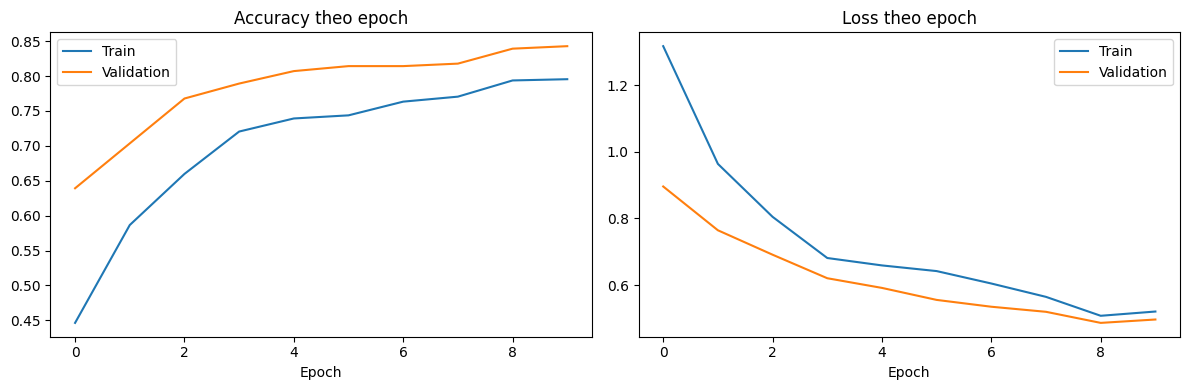

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(history.history['accuracy'],label='Train')
axes[0].plot(history.history['val_accuracy'],label='Validation')
axes[0].set_title('Accuracy theo epoch');axes[0].set_xlabel('Epoch');axes[0].legend()
axes[1].plot(history.history['loss'],label='Train')
axes[1].plot(history.history['val_loss'],label='Validation')
axes[1].set_title('Loss theo epoch');axes[1].set_xlabel('Epoch');axes[1].legend()
fig.tight_layout()
fig.savefig(FOLDER/'training_curves.png',dpi=160,bbox_inches='tight')
plt.show()


## 9. Đánh giá trên tập test độc lập (không dùng test để huấn luyện)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 214ms/step - accuracy: 0.4046 - loss: 1.7245
Test loss: 1.7245 | Test accuracy: 0.4046 | Test ảnh: 173


,precision,recall,f1-score,support
bus,0.083333,0.157895,0.109091,19.000000
car,0.775510,0.567164,0.655172,67.000000
truck,0.280000,0.291667,0.285714,48.000000
van,0.394737,0.384615,0.389610,39.000000
accuracy,0.404624,0.404624,0.404624,0.404624
macro avg,0.383395,0.350335,0.359897,173.000000
weighted avg,0.476169,0.404624,0.432823,173.000000


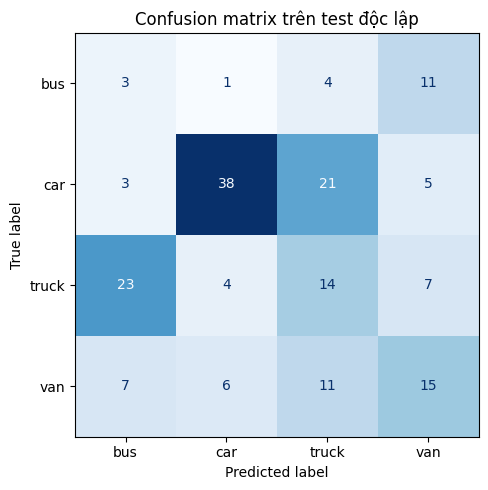

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
loss,acc=model.evaluate(test_ds,verbose=1)
y_true=[];y_pred=[];confidence=[]
for ims,labs in test_ds:
    p=model.predict(ims,verbose=0)
    y_true.extend(labs.numpy().tolist())
    y_pred.extend(np.argmax(p,axis=1).tolist())
    confidence.extend(np.max(p,axis=1).tolist())
print(f'Test loss: {loss:.4f} | Test accuracy: {acc:.4f} | Test ảnh: {len(y_true)}')
report=classification_report(y_true,y_pred,labels=range(len(CLASSES)),
                             target_names=CLASSES,output_dict=True,zero_division=0)
display(pd.DataFrame(report).T)
pd.DataFrame(report).T.to_csv(FOLDER/'classification_report.csv',encoding='utf-8-sig')
cm=confusion_matrix(y_true,y_pred,labels=range(len(CLASSES)))
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm,display_labels=CLASSES).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('Confusion matrix trên test độc lập')
fig.tight_layout()
fig.savefig(FOLDER/'confusion_matrix_test.png',dpi=160,bbox_inches='tight')
plt.show()


## 10. Xem một số ảnh test và nhãn dự đoán

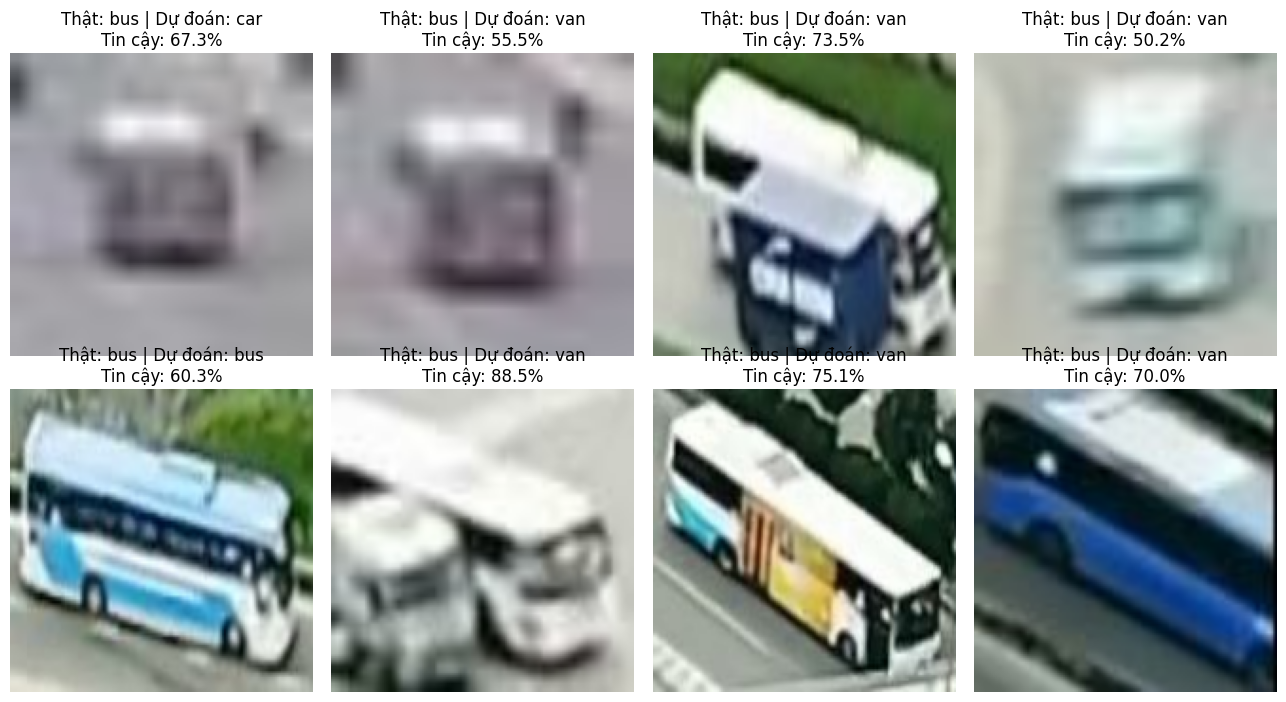

In [ ]:
fig,axes=plt.subplots(2,4,figsize=(13,7))
for ims, labs in test_ds.take(1):
    p=model.predict(ims[:8],verbose=0)
    for i, ax in enumerate(axes.flat):
        ax.imshow(tf.cast(ims[i],tf.uint8).numpy())
        real=CLASSES[int(labs[i])]
        pred=CLASSES[int(np.argmax(p[i]))]
        ax.set_title(f'Thật: {real} | Dự đoán: {pred}\nTin cậy: {float(np.max(p[i])):.1%}')
        ax.axis('off')
fig.tight_layout()
fig.savefig(FOLDER/'demo_predictions_test.png',dpi=160,bbox_inches='tight')
plt.show()


## 11. Lưu mô hình `.keras`, file nhãn, thống kê test vào Google Drive

In [ ]:
import json
MODEL_PATH=FOLDER/'vehicle_4class.keras'
model.save(MODEL_PATH)
(FOLDER/'labels.json').write_text(json.dumps(CLASSES,ensure_ascii=False,indent=2),encoding='utf-8')
stats={
    'task':'Phân loại ảnh 4 lớp – không phải YOLO detection',
    'labels':CLASSES,
    'image_counts':counts,
    'test_total':len(y_true),
    'test_loss':float(loss),
    'test_accuracy':float(acc),
    'training_epochs_run':len(history.history['loss']),
    'keras_model':MODEL_PATH.name
}
(FOLDER/'metrics.json').write_text(json.dumps(stats,ensure_ascii=False,indent=2),encoding='utf-8')
print('Đã lưu:',MODEL_PATH,'| Dung lượng MB:',round(MODEL_PATH.stat().st_size/1024/1024,2))
print('Đã lưu biểu đồ, báo cáo và metrics.json trong:',FOLDER)


Đã lưu: /content/drive/MyDrive/VehicleAI_NopBai/vehicle_4class.keras | Dung lượng MB: 9.25
Đã lưu biểu đồ, báo cáo và metrics.json trong: /content/drive/MyDrive/VehicleAI_NopBai


## 12. Đóng gói bộ dữ liệu kiểm thử riêng để nộp

In [ ]:
from zipfile import ZipFile,ZIP_DEFLATED
TEST_ZIP=FOLDER/'test_data.zip'
with ZipFile(TEST_ZIP,'w',compression=ZIP_DEFLATED) as z:
    for cl in CLASSES:
        for f in sorted((DATA_ROOT/'test'/cl).iterdir()):
            if f.is_file() and f.suffix.lower() in ('.jpg','.jpeg','.png','.webp'):
                z.write(f,arcname=f'test/{cl}/{f.name}')
print('Đã tạo:',TEST_ZIP)
print('Số ảnh test theo từng lớp:',counts['test'])
print('Kiểm tra số file trong ZIP:',len(ZipFile(TEST_ZIP).namelist()))


Đã tạo: /content/drive/MyDrive/VehicleAI_NopBai/test_data.zip
Số ảnh test theo từng lớp: {'bus': 19, 'car': 67, 'truck': 48, 'van': 39}
Kiểm tra số file trong ZIP: 173


## 13. Nạp lại `.keras` để xác nhận file thật sự dùng được

In [ ]:
reloaded=tf.keras.models.load_model(str(MODEL_PATH))
for ims,labs in test_ds.take(1):
    p=reloaded.predict(ims[:1],verbose=0)
    print('Tải lại mô hình thành công.')
    print('Nhãn dự đoán:',CLASSES[int(np.argmax(p[0]))], '– xác suất:',float(np.max(p[0])))
    break
print('SẴN SÀNG NỘP: mô hình + test_data.zip + notebook sau khi lưu kết quả chạy.')


Tải lại mô hình thành công.
Nhãn dự đoán: car – xác suất: 0.6732323169708252
SẴN SÀNG NỘP: mô hình + test_data.zip + notebook sau khi lưu kết quả chạy.


## 14. Lưu và chia sẻ bài nộp

**Google Colab:** chọn `File → Save a copy in Drive` (nếu cần), đặt tên `VehicleAI_Colab_HuanLuyen_Keras.ipynb`, chạy xong tất cả ô; chọn `Share → General access: Anyone with the link → Viewer` (hoặc Commenter nếu thầy yêu cầu). **Giữ lại output đã lưu**, đừng bật `Omit code cell output`.

**Google Drive:** thư mục `My Drive/VehicleAI_NopBai` đã có dữ liệu gốc, `vehicle_4class.keras`, `test_data.zip`, `metrics.json`, các đồ thị. Đặt quyền chia sẻ phù hợp cho người chấm; thử mở ở cửa sổ ẩn danh.

**GitHub:** có thể upload `.ipynb` vào repo [xla_baocaocuoiky](https://github.com/huynguyentrannhat-art/xla_baocaocuoiky) qua `Add file → Upload files → Commit changes`. Mô hình `.keras` và test có thể đặt trên Drive nếu không muốn đưa lên GitHub.

**Lưu ý về khả năng tái hiện:** notebook đọc ZIP từ Drive của bạn. Người khác muốn tự chạy cần được cấp quyền truy cập ZIP; hoặc tự tải cùng dữ liệu vào Drive của họ và dùng đường dẫn tương ứng.
